# Aula 25 — Árvores de comportamento

**ECAA08 — Arquitetura de Sistemas SCADA | Grupo 06**  
**Integrantes:** Arthur, Caique, Luis Felipe e Marina  
**Planta:** Sistema SCADA aplicado a um Drone Agrícola de Pulverização  
**Etapa 3:** Árvores — planejamento e execução supervisionada de missões de pulverização


## 1. Contexto e objetivo no SCADA

A árvore de comportamento organiza as prioridades do supervisor SCADA: avaliar emergência e qualidade da telemetria, tratar bloqueios, aguardar aprovação, propor deslocamento e solicitar aplicação. O resultado é uma solicitação simulada, acompanhada de motivo e trilha de avaliação para a HMI.

A aquisição/controladora local permanece responsável pela atuação real e pelos controles de voo. O código não substitui firmware, não comanda motores e não envia mensagens a equipamentos. A retenção de falha evita que o desaparecimento do sintoma após desligar a bomba seja interpretado como reparo.

## 2. Modelo e fundamentação

As folhas retornam SUCCESS, FAILURE ou RUNNING. Uma sequência avança enquanto recebe SUCCESS e para em FAILURE ou RUNNING. Um seletor avança enquanto recebe FAILURE e para em SUCCESS ou RUNNING. Os compostos são reativos: a cada tick recomeçam pelo filho de maior prioridade.

Condições leem o blackboard e ações escrevem solicitações. Antes de cada tick, a solicitação da bomba é zerada. Assim uma ação de aplicação anteriormente RUNNING não mantém seu comando quando um bloqueio prioritário surge. Não há tarefa assíncrona real que necessite cancelamento no firmware.

Os limiares do diagnóstico seguem a convenção integrada da Aula 10 e a continuidade da Aula 15: pressão alta >5 bar; baixa <1 bar; vazão baixa <0,5 L/min durante operação estabilizada; nível crítico <5%; bateria crítica <10%; vento alto >8 m/s. Nível ou bateria <20% motivam solicitação de retorno quando não existem bloqueios prioritários. Dados ausentes, não finitos ou inválidos impedem autorização. A idade máxima de 2 s é uma hipótese nova desta etapa.

## 3. Procedimento e demonstração

1. Mostrar a ordem das condições e o funcionamento de sequência e seletor.
2. Executar ticks normais, vento alto, bateria crítica, GPS inválido e telemetria vencida.
3. Injetar indício de obstrução, desligar o feedback da bomba e demonstrar a retenção.
4. Tentar rearmar sem inspeção e demonstrar o bloqueio.
5. Confirmar inspeção e emitir pulso de rearme com dados válidos e sem alarmes ativos.

Pergunta para a apresentação: por que a árvore pode retornar RUNNING enquanto solicita pausa? Porque a ação supervisória de aguardar condições permanece em andamento; isso não significa bomba ligada.

## 4. Experimentos executáveis

Execute as células em ordem, com a pasta `Arquivos_de_Apoio` ao lado do notebook. Os algoritmos centrais aparecem abaixo; dados, funções comuns e verificações estão nos arquivos de apoio. Não há download de dados durante a execução.

In [1]:
from pathlib import Path
import sys
# Funciona na pasta da etapa, na raiz do repositório ou em uma subpasta da etapa.
origem = Path.cwd().resolve()
candidatos = [p / sufixo for p in [origem, *origem.parents]
              for sufixo in (Path('.'), Path('etapa-03-arvores'))]
ETAPA = next((p for p in candidatos if (p/'Arquivos_de_Apoio'/'scada_arvores.py').is_file()), None)
if ETAPA is None:
    raise FileNotFoundError('Extraia o pacote completo e abra o notebook na pasta etapa-03-arvores.')
sys.path.insert(0, str(ETAPA/'Arquivos_de_Apoio'))
from scada_arvores import *
import scada_arvores as core
import visualizacao as vis
from verificacoes import TESTES, conferir_rrt
import matplotlib.pyplot as plt
import json
print('Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica')


Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica


In [2]:
class Folha:
    def __init__(self, nome, func): self.nome = nome; self.func = func
    def tick(self, bb):
        status = self.func(bb); bb['trilha'].append((self.nome, status)); return status


class Composto:
    def __init__(self, nome, filhos, seletor=False):
        self.nome = nome; self.filhos = filhos; self.seletor = seletor
    def tick(self, bb):
        continua = FAILURE if self.seletor else SUCCESS
        for filho in self.filhos:
            estado = filho.tick(bb)
            if estado != continua: bb['trilha'].append((self.nome, estado)); return estado
        final = FAILURE if self.seletor else SUCCESS
        bb['trilha'].append((self.nome, final)); return final


In [3]:
def arvore_comportamento():
    def ramo(nome, p, a): return Composto(nome, [condicao(nome+'?', p), a])
    return Composto('Supervisão reativa', [
        ramo('Emergência', lambda b: b['t'].get('e_stop') is True, acao('EMERGENCIA')),
        ramo('Qualidade', lambda b: not b['dados_ok'], acao('PAUSAR_DADOS')),
        ramo('Bateria crítica', lambda b: 'BATERIA_CRITICA' in b['alarmes'], acao('INTERROMPER_MISSAO')),
        ramo('Bloqueios', lambda b: bool(b['alarmes']) or b['retida'], acao('PAUSAR')),
        ramo('Concluída', lambda b: b.get('concluida', False), acao('CONCLUIR', status=SUCCESS)),
        ramo('Sem aprovação', lambda b: not b.get('aprovada', False), acao('AGUARDAR_OPERADOR')),
        ramo('Retorno', lambda b: b.get('retornar', False) or b['t']['DRN_ET_01'] < 20 or b['t']['DRN_LT_01'] < 20,
             acao('SOLICITAR_RETORNO')),
        ramo('Sem rota', lambda b: not b.get('rota_ok', False), acao('PLANEJAR')),
        ramo('Em deslocamento', lambda b: not b.get('na_faixa', False), acao('DESLOCAR')),
        ramo('Fora de voo', lambda b: not b['t']['is_flying'], acao('AGUARDAR_VOO')),
        acao('PULVERIZAR', bomba=True)
    ], seletor=True)


def tick_supervisor(bb, t):
    bb['t'] = dict(t); bb['trilha'] = []; bb['bomba_solicitada'] = False
    alarmes, validos = diagnostico(t)
    bb['dados_ok'] = validos and t['comm_ok'] and t['idade_s'] <= 2 and t['gps_ok']
    hidraulicos = {'FALHA_PULVERIZACAO', 'POSSIVEL_OBSTRUCAO', 'POSSIVEL_VAZAMENTO_OU_FALHA_BOMBA'}
    bb['retida'] = bb.get('retida', False) or bool(set(alarmes) & hidraulicos)
    if bb.get('rearme') and bb.get('inspecao_confirmada') and validos and not alarmes:
        bb['retida'] = False
    bb['alarmes'] = alarmes
    estado = arvore_comportamento().tick(bb)
    # Barreira final independente da folha escolhida; reiniciada a cada tick.
    permitido = (validos and not alarmes and not bb['retida'] and bb.get('aprovada', False)
                 and bb.get('rota_ok', False) and bb.get('na_faixa', False) and t['is_flying'])
    bb['bomba'] = bool(bb['bomba_solicitada'] and permitido)
    bb['rearme'] = False  # pulso consumido; inspeção sozinha não rearma
    return dict(acao=bb['acao'], status=estado, bomba=bb['bomba'],
                alarmes=alarmes+(['FALHA_RETIDA'] if bb['retida'] else []), trilha=list(bb['trilha']))


### Retenção e rearme supervisionado

In [4]:
bb=dict(aprovada=True,rota_ok=True,na_faixa=True)
casos=[('Normal',telemetria()),('Obstrução',telemetria(DRN_PT_01=5.6,DRN_FT_01=.2)),
       ('Sintoma desapareceu',telemetria(bomba_feedback=False,DRN_FT_01=0.))]
for nome,t in casos:
    r=tick_supervisor(bb,t);print(nome,r['acao'],r['bomba'],r['alarmes'])
bb.update(rearme=True,inspecao_confirmada=True)
r=tick_supervisor(bb,telemetria());print('Rearme confirmado:',r)

Normal PULVERIZAR True []
Obstrução PAUSAR False ['FALHA_PULVERIZACAO', 'POSSIVEL_OBSTRUCAO', 'FALHA_RETIDA']
Sintoma desapareceu PAUSAR False ['FALHA_RETIDA']
Rearme confirmado: {'acao': 'PULVERIZAR', 'status': 'RUNNING', 'bomba': True, 'alarmes': [], 'trilha': [('Emergência?', 'FAILURE'), ('Emergência', 'FAILURE'), ('Qualidade?', 'FAILURE'), ('Qualidade', 'FAILURE'), ('Bateria crítica?', 'FAILURE'), ('Bateria crítica', 'FAILURE'), ('Bloqueios?', 'FAILURE'), ('Bloqueios', 'FAILURE'), ('Concluída?', 'FAILURE'), ('Concluída', 'FAILURE'), ('Sem aprovação?', 'FAILURE'), ('Sem aprovação', 'FAILURE'), ('Retorno?', 'FAILURE'), ('Retorno', 'FAILURE'), ('Sem rota?', 'FAILURE'), ('Sem rota', 'FAILURE'), ('Em deslocamento?', 'FAILURE'), ('Em deslocamento', 'FAILURE'), ('Fora de voo?', 'FAILURE'), ('Fora de voo', 'FAILURE'), ('PULVERIZAR', 'RUNNING'), ('Supervisão reativa', 'RUNNING')]}


### Prioridades e preempção

Novo tick com vento alto: PAUSAR | bomba: False
('Emergência?', 'FAILURE')
('Emergência', 'FAILURE')
('Qualidade?', 'FAILURE')
('Qualidade', 'FAILURE')
('Bateria crítica?', 'FAILURE')
('Bateria crítica', 'FAILURE')
('Bloqueios?', 'SUCCESS')
('PAUSAR', 'RUNNING')
('Bloqueios', 'RUNNING')
('Supervisão reativa', 'RUNNING')


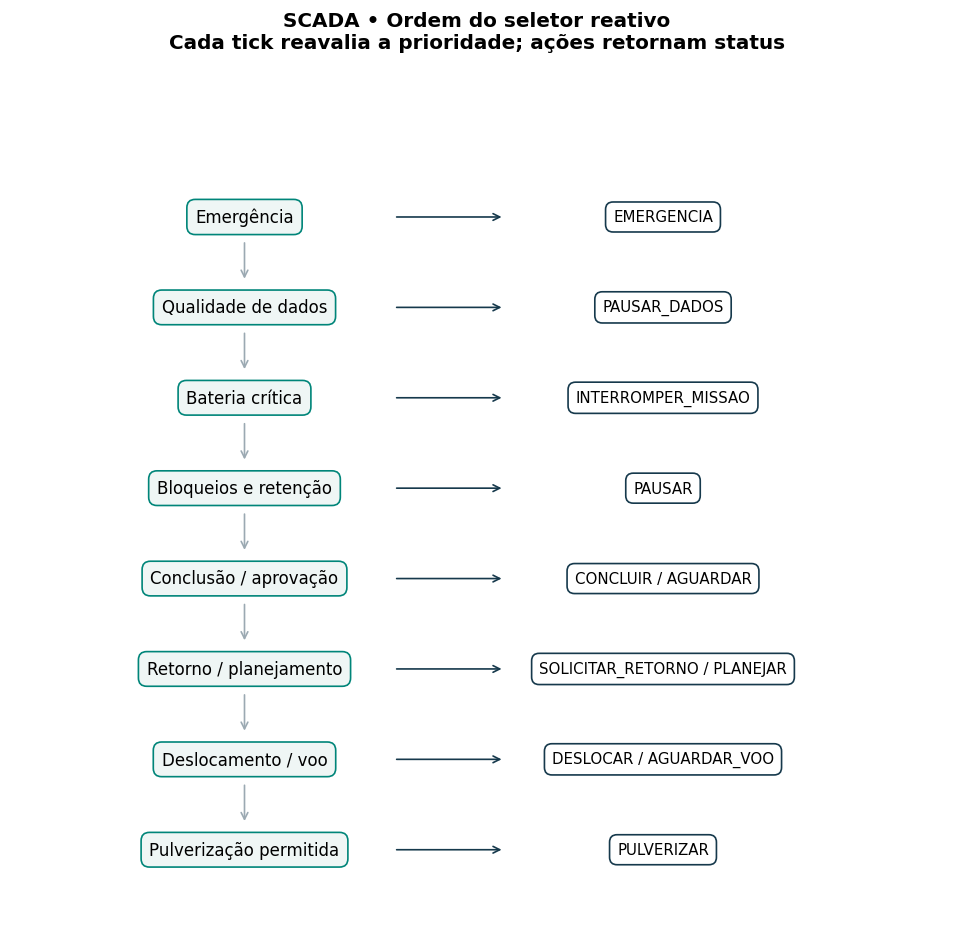

In [5]:
r=tick_supervisor(bb,telemetria(EST_WT_01=9))
print('Novo tick com vento alto:',r['acao'],'| bomba:',r['bomba'])
for item in r['trilha']:print(item)
vis.figura25();plt.show()

### Verificação e resultados de referência

As verificações confrontam propriedades, referências independentes e casos de fronteira. Consulte `Arquivos_de_Apoio/verificacoes.py` para os critérios completos.

In [6]:
RESUMO = TESTES[25]()
print(json.dumps(RESUMO, ensure_ascii=False, indent=2))
print('Verificações da aula 25: APROVADAS')

{
  "bloqueios_testados": 11,
  "retencao_e_rearme": "APROVADOS"
}
Verificações da aula 25: APROVADAS


## 5. Interpretação, limites e continuidade

A bomba solicitada ainda atravessa uma barreira final: dados válidos, ausência de alarmes, ausência de retenção, aprovação, caminho válido, presença na faixa e voo confirmado. A classificação aprendida da Aula 27 nunca altera esse permissivo.

Falha de GPS ou comunicação impede presumir que um retorno automático seja seguro; o simulador pausa e entrega a situação à lógica local/operador. Bateria crítica interrompe a missão, sem inventar um pouso ou retorno garantido. A política de retorno com bateria baixa é didática e não calcula autonomia. A partida dinâmica da bomba não é modelada: diagnósticos de pressão e vazão recebem a indicação externa `estabilizado`.

O diagrama agrupa alguns ramos para legibilidade; a implementação apresenta todos os filhos do seletor. A Aula 28 registra cada tick e verifica sua coerência com a rede de Petri.

## 6. Referências

- [Colledanchise e Ögren — Behavior Trees in Robotics and AI](https://arxiv.org/abs/1709.00084).
- [Continuidade e tags do grupo](Arquivos_de_Apoio/Continuidade_e_Hipoteses.md).